# Double Descent Lab

**Question:** Can test error rise near interpolation, then fall again for wider models?

We investigate this with a synthetic regression problem and a controlled sweep of random ReLU features across 50 seeds.

## Setup and reproducibility

In [1]:
import platform
import sys
from importlib.metadata import PackageNotFoundError, version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

print(f"Python: {sys.version.split()[0]} ({platform.platform()})")
for package in ("numpy", "pandas", "matplotlib"):
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: version unavailable")

Python: 3.13.5 (macOS-26.6.2-arm64-arm-64bit-Mach-O)
numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2


## See double descent in a controlled model

The model has a frozen random ReLU hidden layer and a minimum-norm least-squares output layer. We add noise only to training targets and keep test targets clean. Each seed uses nested feature widths, so the experiment isolates the effect of increasing capacity. See [Belkin et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC6689936/) and [Nakkiran et al.](https://arxiv.org/abs/1912.02292).

Empirical interpolation begins around width 105 (n_train=100).
Median test MSE peaks at width 101, then falls as width grows.


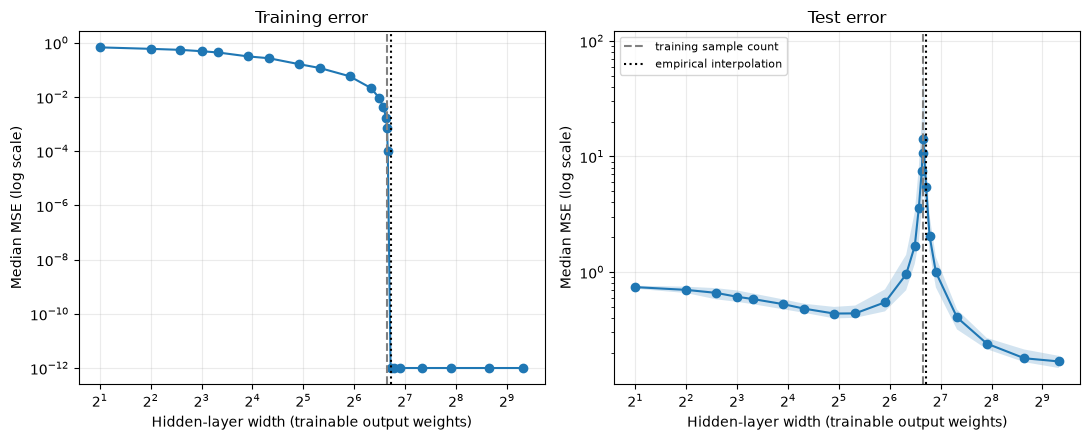

In [2]:

N_TRAIN = 100
N_TEST = 2_000
INPUT_DIM = 10
NOISE_SD = 0.1
WIDTHS = [2, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 90, 95, 99, 100, 101, 105, 110, 120, 160, 240, 400, 640]
SEEDS = range(50)

rows = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(N_TRAIN + N_TEST, INPUT_DIM))
    target = lambda z: np.sin(z[:, 0]) + 0.5 * z[:, 1] * z[:, 2] + 0.25 * z[:, 3]
    y_clean = target(x)
    y_train = y_clean[:N_TRAIN] + rng.normal(0, NOISE_SD, N_TRAIN)
    weights = rng.normal(size=(INPUT_DIM, max(WIDTHS))) / np.sqrt(INPUT_DIM)
    bias = rng.normal(size=max(WIDTHS))
    features = np.maximum(x @ weights + bias, 0)

    for width in WIDTHS:
        train_features = features[:N_TRAIN, :width]
        output_weights, _, rank, _ = np.linalg.lstsq(train_features, y_train, rcond=None)
        train_prediction = train_features @ output_weights
        test_prediction = features[N_TRAIN:, :width] @ output_weights
        rows.append({
            "seed": seed,
            "width": width,
            "feature_rank": rank,
            "train_mse": np.mean((train_prediction - y_train) ** 2),
            "test_mse": np.mean((test_prediction - y_clean[N_TRAIN:]) ** 2),
        })

synthetic_results = pd.DataFrame(rows)
summary = synthetic_results.groupby("width").agg(
    train_mse=("train_mse", "median"),
    test_mse=("test_mse", "median"),
    test_mse_low=("test_mse", lambda values: values.quantile(0.25)),
    test_mse_high=("test_mse", lambda values: values.quantile(0.75)),
).reset_index()
interpolation_width = int(summary.loc[summary.train_mse <= 1e-10, "width"].min())
peak_width = int(summary.loc[summary.test_mse.idxmax(), "width"])

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
synthetic_results.to_csv(results_dir / "synthetic-double-descent.csv", index=False)
summary.to_csv(results_dir / "synthetic-double-descent-summary.csv", index=False)
print(f"Empirical interpolation begins around width {interpolation_width} (n_train={N_TRAIN}).")
print(f"Median test MSE peaks at width {peak_width}, then falls as width grows.")

grid, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
axes[0].plot(summary.width, np.maximum(summary.train_mse, 1e-12), marker="o")
axes[0].set_yscale("log")
axes[0].set_title("Training error")
axes[0].set_ylabel("Median MSE (log scale)")
axes[1].plot(summary.width, summary.test_mse, marker="o")
axes[1].fill_between(summary.width, summary.test_mse_low, summary.test_mse_high, alpha=0.2)
axes[1].set_yscale("log")
axes[1].set_title("Test error")
axes[1].set_ylabel("Median MSE (log scale)")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Hidden-layer width (trainable output weights)")
    ax.axvline(N_TRAIN, color="gray", linestyle="--", label="training sample count")
    ax.axvline(interpolation_width, color="black", linestyle=":", label="empirical interpolation")
    ax.grid(alpha=0.25)
axes[1].legend(fontsize=8)
grid.tight_layout()
plt.show()


## Findings

- Across 50 seeds, median test MSE peaks at **14.19 at width 101**. Median training MSE first reaches numerical zero at **width 105**; test MSE then falls to **0.17 at width 640**. This shows double descent near the empirically measured interpolation point.
- The hidden ReLU features are frozen; only the output weights are fit. This controlled result demonstrates the effect for this setup, not for every dataset or end-to-end-trained network. Noise is added only to training targets.